# 02 · Portfolio Growth & Approval Funnel

**Objective:** size the business and track the approval rate over time.

**Bottom line:** funded volume grew from \$20M (2008) to \$7.9B (2018). Over the same period the **approval rate fell from a 15.1% peak in 2013 to 5.0% in 2018**. The decline is driven by the **denominator**: applications tripled between 2015 and 2018 while approvals grew only 18%. Lending Club did not approve fewer people; it attracted far more applicants than it chose to fund.

*Note: 2007 covers June–December only, so growth is measured from 2008.*

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Funded volume by year

In [2]:
volume = con.sql("""
SELECT YEAR(issue_date)                          AS issue_year,
       COUNT(*)                                  AS n_loans,
       ROUND(SUM(funded_amnt) / 1000000, 1)      AS funded_mm,
       ROUND(SUM(funded_amnt) / COUNT(*), 0)     AS avg_loan_size
FROM loans_clean
GROUP BY issue_year
ORDER BY issue_year
""").df()
volume

,issue_year,n_loans,funded_mm,avg_loan_size
0,2007,603,4.8,7946.0
1,2008,2393,20.0,8347.0
2,2009,5281,51.8,9812.0
3,2010,12537,126.4,10078.0
4,2011,21721,257.4,11849.0
5,2012,53367,717.9,13453.0
6,2013,134814,1982.8,14707.0
7,2014,235629,3503.8,14870.0
8,2015,421095,6417.6,15240.0
9,2016,434407,6400.5,14734.0


* Loan count grew **~207×** and funded amount **~397×** from 2008 to 2018: average loan size almost doubled.
* Growth roughly doubled every year through 2015, then **stalled in 2016** (investigated in notebook 04).
* Sanity check: 2014 + 2015 loans = 656,724, matching the cohort filter before the 36-month restriction.

## 2. Approval rate
Approval rate = approved ÷ (approved + rejected). Yearly counts are built in two CTEs and joined on year. A `LEFT JOIN` keeps every year in the accepted table, even if the rejected table were missing one.

In [3]:
approval = con.sql("""
WITH accepted AS (
    SELECT YEAR(issue_date) AS issue_year,
           COUNT(*)         AS n_accepted
    FROM loans_clean
    GROUP BY issue_year
),
declined AS (
    SELECT YEAR("Application Date") AS issue_year,
           COUNT(*)                 AS n_rejected
    FROM rejected
    GROUP BY issue_year
)
SELECT a.issue_year,
       a.n_accepted,
       d.n_rejected,
       a.n_accepted + d.n_rejected                                   AS n_applications,
       ROUND(a.n_accepted * 1.0 / (a.n_accepted + d.n_rejected), 4)  AS approval_rate
FROM accepted a
LEFT JOIN declined d ON a.issue_year = d.issue_year
ORDER BY a.issue_year
""").df()
approval

,issue_year,n_accepted,n_rejected,n_applications,approval_rate
0,2007,603,5274,5877,0.1026
1,2008,2393,25596,27989,0.0855
2,2009,5281,56991,62272,0.0848
3,2010,12537,112561,125098,0.1002
4,2011,21721,217792,239513,0.0907
5,2012,53367,337277,390644,0.1366
6,2013,134814,760942,895756,0.1505
7,2014,235629,1933700,2169329,0.1086
8,2015,421095,2859379,3280474,0.1284
9,2016,434407,4769874,5204281,0.0835


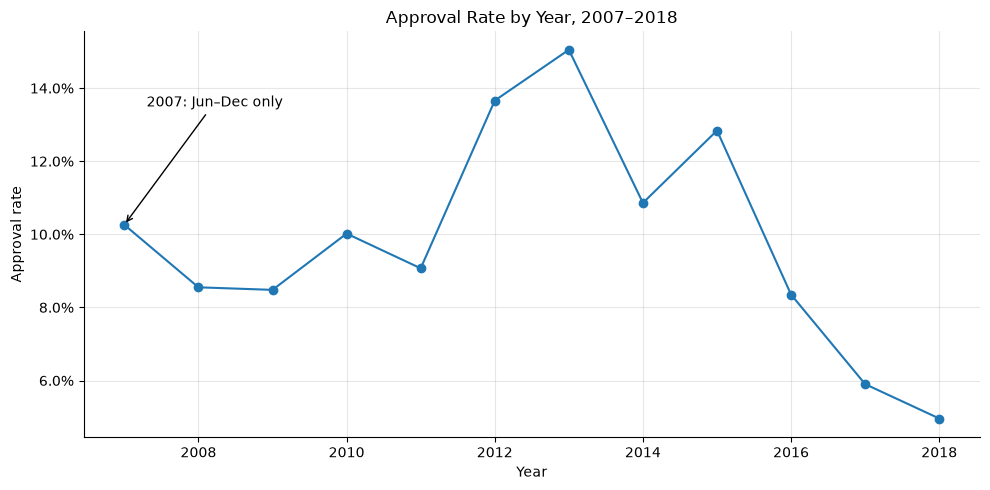

In [4]:
fig, ax = plt.subplots()
ax.plot(approval["issue_year"], approval["approval_rate"], marker="o")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Approval Rate by Year, 2007–2018")
ax.set_xlabel("Year")
ax.set_ylabel("Approval rate")
ax.annotate("2007: Jun–Dec only", xy=(2007, approval.loc[0, "approval_rate"]),
            xytext=(2007.3, 0.135), arrowprops={"arrowstyle": "->"})
fig.tight_layout()
fig.savefig(IMAGE_DIR / "approval_rate_by_year.png", dpi=150)
plt.show()

## 3. Decomposing the decline
A ratio can move because of its numerator or its denominator, so check both.

In [5]:
decomp = approval.set_index("issue_year").loc[[2015, 2018], ["n_accepted", "n_applications", "approval_rate"]].T
decomp["change"] = decomp[2018] / decomp[2015] - 1
decomp

issue_year,2015,2018,change
n_accepted,4.210950e+05,4.952420e+05,0.176081
n_applications,3.280474e+06,9.992024e+06,2.045909
approval_rate,1.284000e-01,4.960000e-02,-0.613707


**Reading:** approvals +18%, applications +205%. The falling approval rate reflects a surge in (likely lower-quality) applicants combined with steady or tighter credit standards, **not** a collapse in approvals.

**Caveat:** the rejected file only records the application date, and an application approved in December may be funded in January, so year-level rates are approximate.